# UK Turnout Analysis Project

## NB03: Exploratory Analysis

This notebook explores constituency-level turnout and its relationship with the
demographic and socioeconomic predictors constructed in NB02.

The analysis first examines distributions and unusual observations, then
considers correlations and bivariate relationships before any multivariable
models are estimated.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv("../data/processed/analysis_data.csv")

data.shape

(575, 19)

In [2]:
assert len(data) == 575
assert data["constituency_code"].is_unique
assert data.notna().all().all()

data.head()

,constituency_code,constituency_name,region_name,country_name,electorate,valid_votes,invalid_votes,majority,first_party,second_party,turnout_pct,level4_plus_pct,age_18_34_pct,age_65_plus_pct,owner_occupied_pct,social_rented_pct,unemployment_rate,student_pct,population_density
0,W07000081,Aberafan Maesteg,Wales,Wales,72580,35755,79,10354,Lab,RUK,49.371728,23.706702,24.786278,26.024156,64.442539,19.875031,5.653070,5.690625,383.006332
1,E14001063,Aldershot,South East,England,78553,48544,179,5683,Lab,Con,62.025639,29.943237,29.705079,20.345473,64.903732,15.069413,4.456739,5.095075,2056.408306
2,E14001064,Aldridge-Brownhills,West Midlands,England,70268,40912,156,4294,Con,Lab,58.444811,27.151638,22.746104,28.491433,75.730136,13.416656,4.934167,5.426618,1755.309210
3,E14001065,Altrincham and Sale West,North West,England,74025,51452,184,4174,Lab,Con,69.754813,48.655691,20.612168,25.002278,74.766332,11.375512,4.071462,6.383032,1981.820029
4,W07000082,Alyn and Deeside,Wales,Wales,75790,43392,135,8794,Lab,RUK,57.431060,27.437783,24.820370,24.896782,71.136493,15.058824,4.546847,5.385629,550.865755


### 1. Turnout distribution

The distribution of constituency-level turnout is examined first to identify its
overall range, central tendency and any unusually high- or low-turnout
constituencies.

In [3]:
data["turnout_pct"].describe()

count    575.000000
mean      60.116025
std        7.010406
min       40.251763
25%       55.005884
50%       60.674673
75%       65.747235
max       75.474101
Name: turnout_pct, dtype: float64

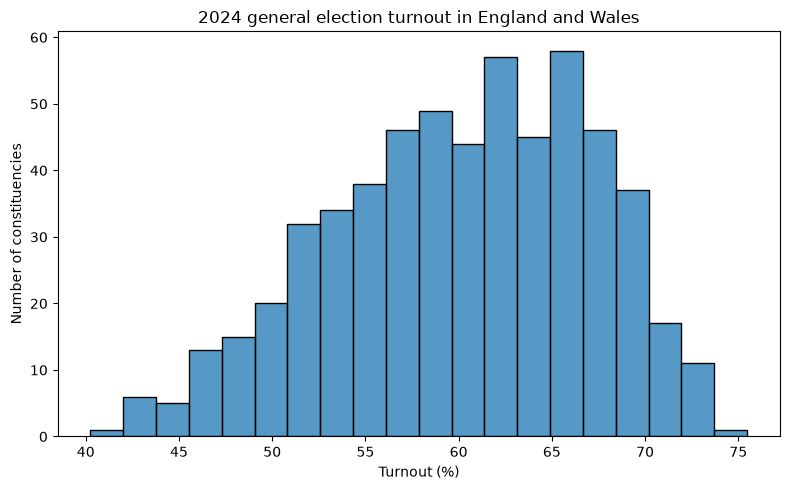

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))

sns.histplot(
    data=data,
    x="turnout_pct",
    bins=20,
    ax=ax
)

ax.set_xlabel("Turnout (%)")
ax.set_ylabel("Number of constituencies")
ax.set_title("2024 general election turnout in England and Wales")

plt.tight_layout()

plt.savefig(
    "../figures/turnout_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [5]:
data.nlargest(
    10, "turnout_pct"
)[["constituency_name", "turnout_pct"]]

,constituency_name,turnout_pct
222,Harpenden and Berkhamsted,75.474101
421,Rushcliffe,73.213744
554,Winchester,73.140543
183,Esher and Walton,72.981551
112,Chesham and Amersham,72.929269
446,South Cotswolds,72.876575
361,North Somerset,72.478704
354,North East Hampshire,72.413972
202,Godalming and Ash,72.325103
234,Henley and Thame,72.314201


In [6]:
data.nsmallest(
    10, "turnout_pct"
)[["constituency_name", "turnout_pct"]]

,constituency_name,turnout_pct
308,Manchester Rusholme,40.251763
267,Kingston upon Hull East,42.326964
277,Leeds South,42.330125
512,Tipton and Wednesbury,43.171206
562,Wolverhampton South East,43.255070
46,Blaenau Gwent and Rhymney,43.388023
43,Blackley and Middleton South,43.551443
36,Birmingham Ladywood,43.948717
35,Birmingham Hodge Hill and Solihull North,44.075537
33,Birmingham Erdington,44.265004


Turnout is broadly concentrated around 60–65%, with a few constituencies at each extreme. The distribution shows a longer lower-turnout tail, suggesting that unusually low-turnout constituencies may warrant closer inspection in later analysis.

### 3. Predictor distributions

The distributions of the seven constituency-level predictors are examined before
considering their relationships with turnout. This helps identify skewed variables,
unusual observations and potential transformations that may be useful in later
modelling.

In [7]:
predictor_cols = [
    "level4_plus_pct",
    "age_18_34_pct",
    "age_65_plus_pct",
    "owner_occupied_pct",
    "social_rented_pct",
    "unemployment_rate",
    "population_density"
]

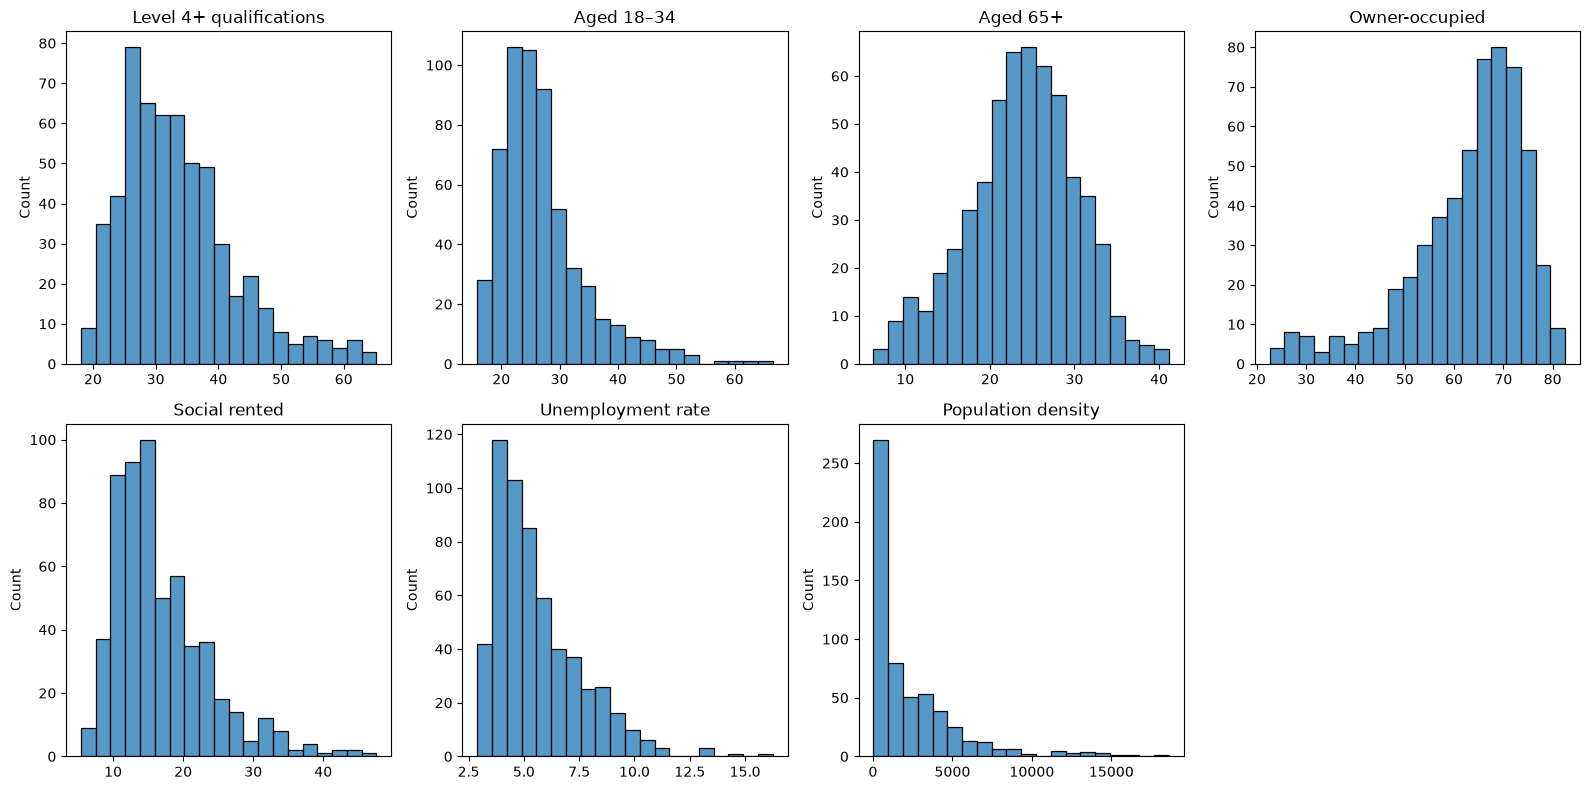

In [8]:
predictor_labels = {
    "level4_plus_pct": "Level 4+ qualifications",
    "age_18_34_pct": "Aged 18–34",
    "age_65_plus_pct": "Aged 65+",
    "owner_occupied_pct": "Owner-occupied",
    "social_rented_pct": "Social rented",
    "unemployment_rate": "Unemployment rate",
    "population_density": "Population density"
}

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for ax, col in zip(axes, predictor_cols):
    sns.histplot(data=data, x=col, bins=20, ax=ax)

    ax.set_title(predictor_labels[col])
    ax.set_xlabel("")

axes[-1].axis("off")

plt.tight_layout()

plt.savefig(
    "../figures/predictor_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [9]:
data[predictor_cols].skew().sort_values(ascending=False)

population_density    2.297300
age_18_34_pct         1.618083
unemployment_rate     1.387617
social_rented_pct     1.358462
level4_plus_pct       1.033745
age_65_plus_pct      -0.234509
owner_occupied_pct   -1.221815
dtype: float64

#### Population-density transformation

Most predictors show some asymmetry, but they are retained in their original percentage-point units because these measures remain directly interpretable and predictor normality is not required for regression.

The raw population-density measure is strongly right-skewed, reflecting the small number of extremely dense urban constituencies. Taking the natural logarithm substantially reduces this skew, from 2.30 to -0.21.

The log-transformed measure is therefore used in subsequent correlation and modelling analysis, while the original density variable is retained for descriptive interpretation.

In [10]:
data["log_population_density"] = np.log(
    data["population_density"]
)

data[
    ["population_density", "log_population_density"]
].skew()

population_density        2.297300
log_population_density   -0.209628
dtype: float64

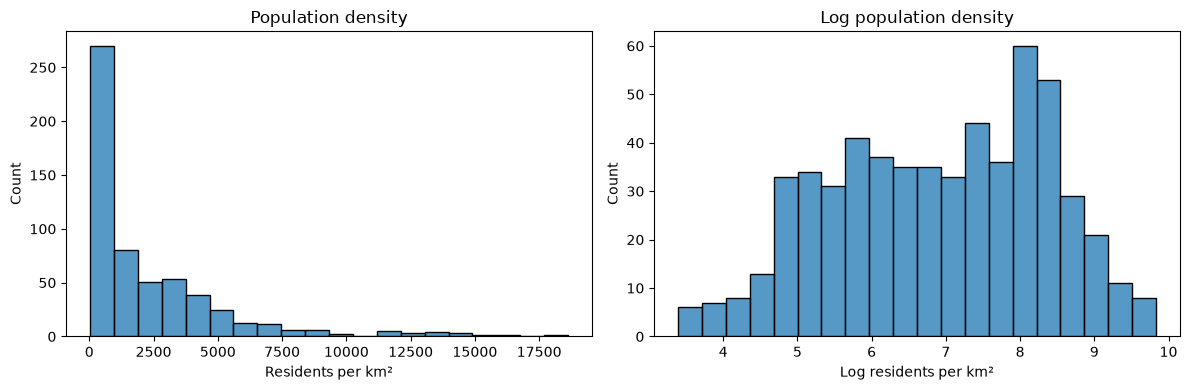

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    data=data,
    x="population_density",
    bins=20,
    ax=axes[0]
)
axes[0].set_title("Population density")
axes[0].set_xlabel("Residents per km²")

sns.histplot(
    data=data,
    x="log_population_density",
    bins=20,
    ax=axes[1]
)
axes[1].set_title("Log population density")
axes[1].set_xlabel("Log residents per km²")

plt.tight_layout()

plt.show()

### 3. Correlation structure

Pairwise correlations are examined to identify relationships among the predictors
before multivariable modelling. Strong correlations may indicate overlapping
constituency characteristics and potential multicollinearity.

In [12]:
analysis_predictors = [
    "level4_plus_pct",
    "age_18_34_pct",
    "age_65_plus_pct",
    "owner_occupied_pct",
    "social_rented_pct",
    "unemployment_rate",
    "log_population_density"
]

In [13]:
correlation_matrix = data[
    ["turnout_pct"] + analysis_predictors
].corr()

correlation_matrix.round(2)

,turnout_pct,level4_plus_pct,age_18_34_pct,age_65_plus_pct,owner_occupied_pct,social_rented_pct,unemployment_rate,log_population_density
turnout_pct,1.00,0.47,-0.49,0.47,0.58,-0.64,-0.71,-0.48
level4_plus_pct,0.47,1.00,0.31,-0.37,-0.27,0.04,-0.01,0.25
age_18_34_pct,-0.49,0.31,1.00,-0.88,-0.85,0.64,0.75,0.71
age_65_plus_pct,0.47,-0.37,-0.88,1.00,0.81,-0.65,-0.70,-0.81
owner_occupied_pct,0.58,-0.27,-0.85,0.81,1.00,-0.83,-0.81,-0.71
social_rented_pct,-0.64,0.04,0.64,-0.65,-0.83,1.00,0.69,0.57
unemployment_rate,-0.71,-0.01,0.75,-0.70,-0.81,0.69,1.00,0.70
log_population_density,-0.48,0.25,0.71,-0.81,-0.71,0.57,0.70,1.00


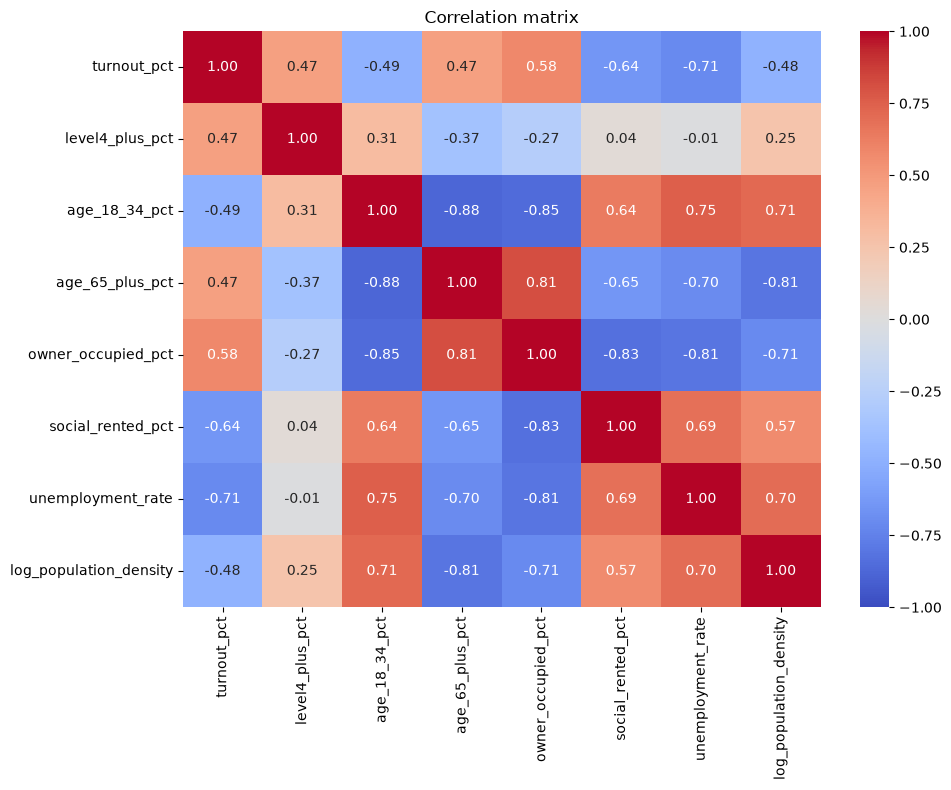

In [14]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation matrix")

plt.tight_layout()

plt.savefig(
    "../figures/correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

The predictors display substantial correlation, reflecting the clustering of demographic and socioeconomic characteristics across constituencies.

Younger constituencies are usually more densely populated, with lower owner-occupation rates and higher unemployment, while older constituencies show the opposite pattern. Several pairwise correlations exceed |0.8|, so multicollinearity will need to be handled in the multivariable modelling stage.


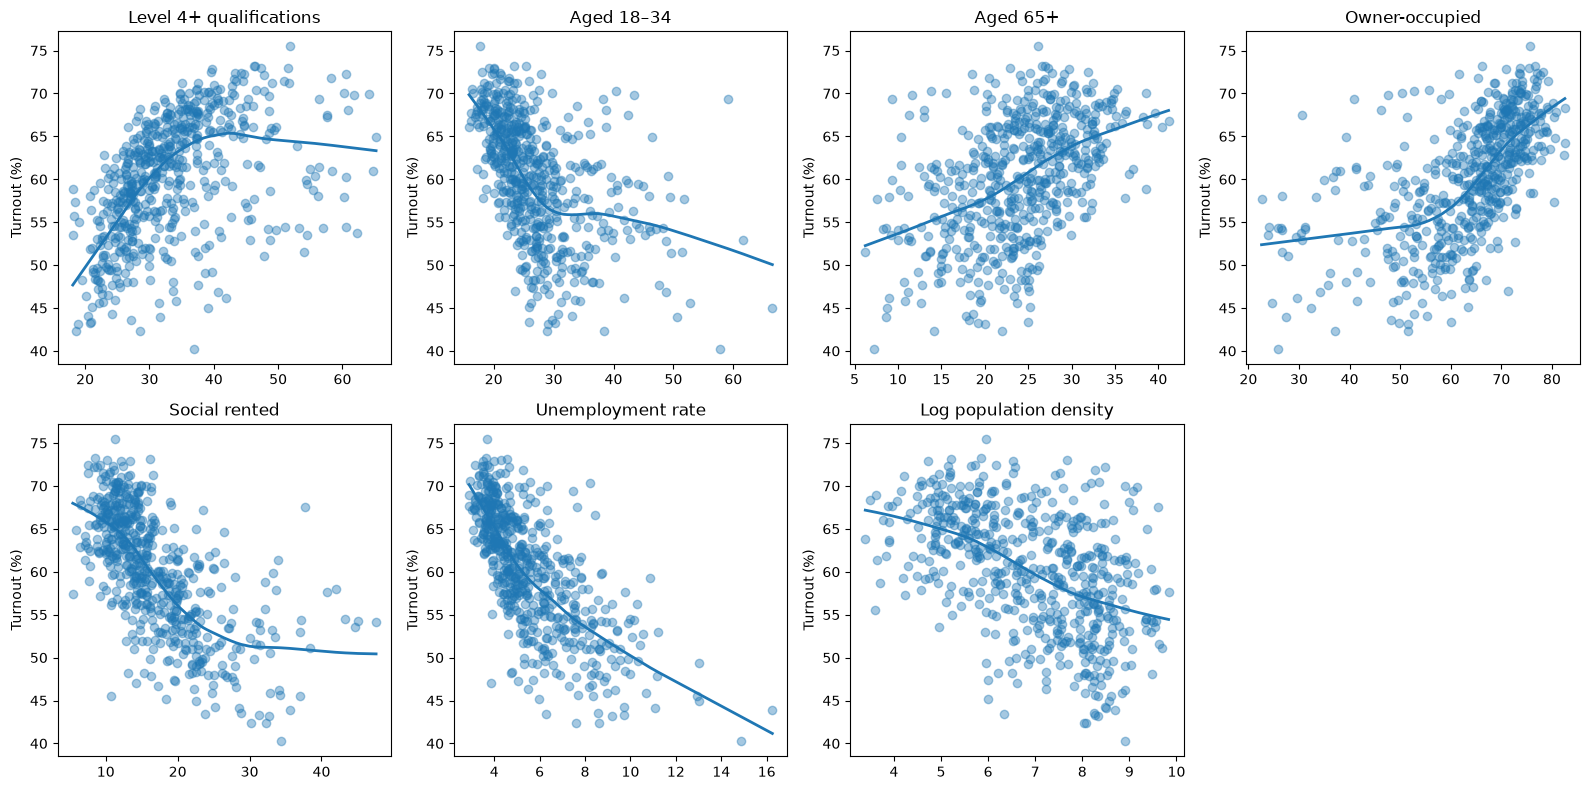

In [15]:
predictor_labels["log_population_density"] = "Log population density"

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for ax, col in zip(axes, analysis_predictors):
    sns.regplot(
        data=data,
        x=col,
        y="turnout_pct",
        lowess=True,
        scatter_kws={"alpha": 0.4},
        line_kws={"linewidth": 2},
        ax=ax
    )

    ax.set_title(predictor_labels.get(col, "Log population density"))
    ax.set_ylabel("Turnout (%)")
    ax.set_xlabel("")

axes[-1].axis("off")

plt.tight_layout()

plt.savefig(
    "../figures/turnout_predictor_relationships.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#### Bivariate relationships with turnout

The bivariate relationships show substantial variation in both strength and functional form.

Unemployment and log-transformed population density exhibit relatively smooth negative relationships with turnout, while the share aged 65 and over is positively associated with turnout. Several other predictors display more pronounced nonlinearity. Turnout rises with educational attainment before plateauing at higher levels, while the relationships with housing types also appear to change across their observed ranges, suggesting potential heteroskedasticity.

These patterns suggest that a purely linear specification may not capture all of the structure in the data. However, the plots are bivariate and predictors are strongly correlated, so any apparent relationships can't yet be interpreted as independent or causal effects.

### 4. Exploratory analysis summary

Turnout varies substantially across constituencies and is associated with a number of demographic and socioeconomic characteristics.

The exploratory analysis identifies three issues for subsequent modelling:

1. several predictors are strongly correlated, creating potential multicollinearity;
2. population density is strongly right-skewed and is better represented on a logarithmic scale;
3. several bivariate relationships show evidence of nonlinearity.

The modelling stage will therefore begin with an interpretable linear baseline, before examining diagnostics, alternative functional forms and predictive models that can accommodate correlated and nonlinear relationships.